In [113]:
import os
from pprint import pprint

from typing import TypedDict, Annotated, Literal, NotRequired
from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_groq import ChatGroq
from langchain_openrouter import ChatOpenRouter

from langchain_core.prompts import PromptTemplate

from dotenv import load_dotenv

In [114]:
load_dotenv()

True

In [115]:
## Area Budget Schema
class AreaBudget(BaseModel):
    area_name: str = Field(description='It represents some areas to track like shopping, food, travel etc')
    budget: int = Field(description='It represents the budget of the area on that very day')

## Day wise budget schema
class DayBudgetSchema(BaseModel):
    date: str = Field(description='The date at which we are planning for the budget')
    weekday: Literal['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'] = Field(
        description='It represents the weekday like Sunday, Monday, Tuesday etc.')
    area_Of_budget: list[AreaBudget] = Field(description='It represents area wise budget')

In [116]:
## class WeatherSchema
class DayWeather(BaseModel):
    date: str = Field(description='The date at which we are looking for the weather')
    weekday: Literal['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'] = Field(
        description='It represents the weekday like Sunday, Monday, Tuesday etc.')
    weather: Literal['sunny', 'rainy', 'cloudy', 'windy', 'stormy', 'snowy', 'foggy', 'humid', 'dry'] = Field(
        'How the weather is')
    
class WeatherInfo(BaseModel):
    weather: list[DayWeather] = Field(description='date and week day wise weather info')

In [117]:
class DatesAndWeekDaysSchema(BaseModel):
    date: str = Field(description='Date')
    weekday: str = Field(description='weekday of the date')

In [118]:
## Day Wise plan schema
class DayWisePlan(BaseModel):
    date: str = Field(description='Date')
    weekday: str = Field(description='weekday of the date')
    plan: str = Field(description='plan for this day')

class TotalDayWisePlan(BaseModel):
    day_plan : list[DayWisePlan] = Field(description='Date and week wise plan')

In [119]:
## Creating / defining the state schema
class TravelPlanner(TypedDict):
    max_budget: int
    max_iteration: int
    iteration: int

    plan_overview: NotRequired[str]
    destination: NotRequired[str]
    days_and_weekdays: NotRequired[list[DatesAndWeekDaysSchema]]
    daily_plan: NotRequired[TotalDayWisePlan]
    budget_info: NotRequired[list[DayBudgetSchema]]
    daily_plan_score: NotRequired[float]
    budget_score: NotRequired[float]
    total_score: NotRequired[float]
    summary: NotRequired[str]

In [120]:
## Creating schema for the travel planner llm
class TravelPlanSchema(BaseModel):
    plan_overview: str
    destination: str
    dates_and_weekdays: list[DatesAndWeekDaysSchema]
    
## Creating Schema for Daily Planner
class DailyPlanner(BaseModel):
    daily_plan: TotalDayWisePlan
    budget_info: list[DayBudgetSchema]
    
    # weather_info: WeatherInfo
    
    

In [121]:
class DailyPlanEvaluateSchema(BaseModel):
    score: float = Field(description='The score for the plan out of 10.', gt=0, le=10)

In [122]:
class BudgetEvaluateSchema(BaseModel):
    score: float = Field(description='The score for the plan out of 10.', gt=0, le=10)

In [123]:
## Models I want to use
# travel_planner_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash').with_structured_output(TravelPlanSchema)
# daily_planner_llm = ChatGroq(model='openai/gpt-oss-120b').with_structured_output(DailyPlanner)
# daily_plan_evaluator_llm = ChatOpenRouter(model='nvidia/nemotron-3-ultra-550b-a55b:free').with_structured_output(DailyPlanEvaluateSchema)
# budget_plan_evaluator_llm = ChatOpenRouter(model='nvidia/nemotron-3.5-super-vl:free').with_structured_output(BudgetEvaluateSchema)
# summary_llm = ChatOpenRouter(model='gemini-3.5-flash')

In [138]:
travel_planner_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash').with_structured_output(TravelPlanSchema)
daily_planner_llm = ChatGoogleGenerativeAI(
    model='gemini-2.5-flash'
).with_structured_output(DailyPlanner)
daily_plan_evaluator_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash').with_structured_output(DailyPlanEvaluateSchema)
budget_plan_evaluator_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash').with_structured_output(BudgetEvaluateSchema)
summary_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

## Testing the Code Snippets

In [26]:
prompt = PromptTemplate(
        template= '''
            You are an smart travel planner working in a MNC travel planning agency. I want you to find a destination and plan the visit
            accordinlgy with the dates and associated weekdays. My max budget is {max_budget}
        ''', input_variables= ['max_budget']
    )
chain = prompt | travel_planner_llm
result = chain.invoke({
        'max_budget': 200000
    })
result

TravelPlanSchema(plan_overview='An 8-day luxurious trip to Japan, exploring the vibrant cities of Tokyo, the cultural heart of Kyoto, and the culinary delights of Osaka. This plan includes high-end accommodations, bullet train travel, exquisite dining experiences, and guided tours to iconic landmarks, all within your specified budget.', destination='Japan (Tokyo, Kyoto, Osaka)', dates_and_weekdays=[DatesAndWeekDaysSchema(date='2024-07-15', weekday='Monday'), DatesAndWeekDaysSchema(date='2024-07-16', weekday='Tuesday'), DatesAndWeekDaysSchema(date='2024-07-17', weekday='Wednesday'), DatesAndWeekDaysSchema(date='2024-07-18', weekday='Thursday'), DatesAndWeekDaysSchema(date='2024-07-19', weekday='Friday'), DatesAndWeekDaysSchema(date='2024-07-20', weekday='Saturday'), DatesAndWeekDaysSchema(date='2024-07-21', weekday='Sunday'), DatesAndWeekDaysSchema(date='2024-07-22', weekday='Monday')])

## Testing Ends

In [125]:
## For planner node
def plan_travel(state: TravelPlanner) -> TravelPlanner:
    prompt = PromptTemplate(
        template= '''
            You are an smart travel planner working in a MNC travel planning agency. I want you to find a destination and plan the visit
            accordinlgy with the dates and associated weekdays. My max budget is {max_budget} INR.
        ''', input_variables= ['max_budget']
    )
    chain = prompt | travel_planner_llm
    result = chain.invoke({
        'max_budget': state['max_budget']
    })
    state['plan_overview'] = result.plan_overview
    state['days_and_weekdays'] = result.dates_and_weekdays
    state['destination'] = result.destination
    
    return state


In [126]:
## For daily planner
def daily_planner(state: TravelPlanner) -> TravelPlanner:
    prompt = PromptTemplate(
        template= '''
            You are an smart travel planner working in a MNC travel planning agency. We are going on a vacation on 
            {destination}. The dates and the associated weeks days are : {day_and_weekdays}.
            I want you to plan our travel day wise. Also Plan the budget accordingly
        ''', input_variables=['destination', 'day_and_weekdays']
    )
    
    destination = state['destination']
    day_and_weekdays = state['days_and_weekdays']
    
    chain = prompt | daily_planner_llm
    response = chain.invoke({
        'destination': destination,
        'day_and_weekdays': day_and_weekdays
    })
        
    return {'daily_plan': response.daily_plan, 'budget_info' : response.budget_info, 'iteration': state['iteration'] + 1}

In [127]:
## For daily planner evaluator
def daily_plan_evaluator(state: TravelPlanner) -> TravelPlanner:
    prompt = PromptTemplate(
        template='''
            You are an expert travel planner working in a Big travel Agency.
            I have planned a travel to {destination} and 
            the travel overview is {travel_overview}.
            My daily plan is something like that: {daily_plan}.
            Give a score out of 10.
        ''', input_variables=['destination', 'travel_overview', 'daily_plan']
    )
    
    chain = prompt | daily_plan_evaluator_llm
    response = chain.invoke({
        'destination': state['destination'],
        'travel_overview': state['plan_overview'],
        'daily_plan': state['daily_plan']
    })
    
    return {'daily_plan_score': response.score}

In [128]:
## For budget evaluator
def budget_plan_evaluator(state: TravelPlanner) -> TravelPlanner:
    prompt = PromptTemplate(
        template='''
        You are an expert travel planner working in a Big travel Agency.
        I have planned a travel to {destination} and 
        the travel overview is {travel_overview}.
        My daily plan is something like that: {daily_plan}.
        My budget estimation information is: {budget_info}
        Give a score out of 10 for the budget only.
        ''', input_variables=['destination', 'travel_overview', 'daily_plan', 'budget_info']
    )
    
    chain = prompt | budget_plan_evaluator_llm
    response = chain.invoke({
        'destination': state['destination'],
        'travel_overview': state['plan_overview'],
        'daily_plan': state['daily_plan'],
        'budget_info': state['budget_info']
    })
    return {'budget_score': response.score}

In [129]:
## For getting overall score
def overall_plan_evaluator(state: TravelPlanner) -> TravelPlanner:
    daily_plan_score = state['daily_plan_score']
    budget_score = state['budget_score']
    tatal_score = (daily_plan_score + budget_score) / 2
    return {'total_score': round(tatal_score, 2)}

In [130]:
## for generating the summary
def summary(state: TravelPlanner) -> TravelPlanner:
    prompt =  PromptTemplate(
        template='''
            You are an expert travel planner working in a Big travel Agency.
            I have planned a travel to {destination} and 
            the travel overview is {travel_overview}.
            Generate a summary on the following context only {context}
        ''', input_variables=['destination', 'travel_overview', 'context']
    )
    
    chain = prompt | summary_llm
    response = chain.invoke({
        'destination': state['destination'],
        'travel_overview': state['plan_overview'],
        'context': state,
    })
    
    summary = response.content
    state['summary'] = summary
    return state

In [131]:
## For defining the conditions
def evaluate_condition(state: TravelPlanner) -> Literal['daily_planner', 'summary'] :
    if (state['daily_plan_score'] < 7 or state['budget_score'] < 7) and state['iteration'] < state['max_iteration']:
        return 'daily_planner'
    else:
        return 'summary'


In [132]:
## Creating the graph
graph = StateGraph(TravelPlanner)

## Creating Nodes
graph.add_node('planner', plan_travel)

graph.add_node('daily_planner', daily_planner)

graph.add_node('daily_plan_evaluator', daily_plan_evaluator)
graph.add_node('budget_plan_evaluator', budget_plan_evaluator)
graph.add_node('overall_plan_evaluator', overall_plan_evaluator)
graph.add_node('summary', summary)

## Creating connections
graph.add_edge(START, 'planner')
graph.add_edge('planner', 'daily_planner')

graph.add_edge('daily_planner', 'daily_plan_evaluator')
graph.add_edge('daily_planner', 'budget_plan_evaluator')

graph.add_edge('daily_plan_evaluator', 'overall_plan_evaluator')
graph.add_edge('budget_plan_evaluator', 'overall_plan_evaluator')

graph.add_conditional_edges('overall_plan_evaluator', evaluate_condition)

graph.add_edge('summary', END)

## compiling the graph
workflow = graph.compile()

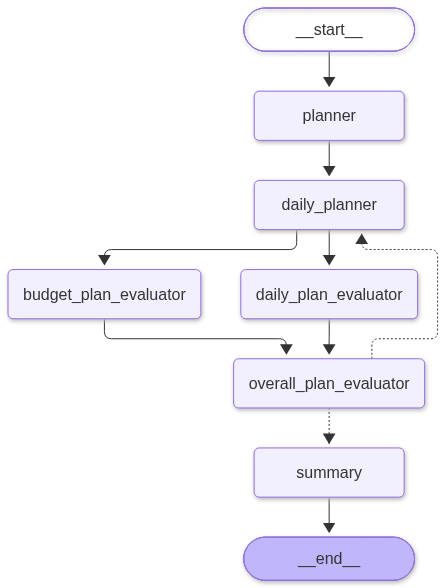

In [133]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [134]:
## Initializing the Initial State
initial_state : TravelPlanner = {
    'max_budget' : 200000,
    'max_iteration': 3,
    'iteration': 0
}

In [139]:
final_state: TravelPlanner = workflow.invoke(initial_state)

In [140]:
for key, value in final_state.items():
    print(f"\n{'=' * 20} {key} {'=' * 20}")
    pprint(value, sort_dicts=False)


==================== max_budget ====================
200000

==================== max_iteration ====================
3

==================== iteration ====================
1

==================== plan_overview ====================
('A captivating 7-day adventure to Thailand, designed to give you a perfect '
 'blend of bustling city life in Bangkok and serene beach relaxation in '
 'Phuket, all within your budget of 200,000 INR. This plan includes '
 'international flights, comfortable accommodations, inter-city transfers, and '
 'exciting activities to ensure a memorable experience.')

==================== destination ====================
'Thailand (Bangkok & Phuket)'

==================== days_and_weekdays ====================
[DatesAndWeekDaysSchema(date='2024-06-15', weekday='Saturday'),
 DatesAndWeekDaysSchema(date='2024-06-16', weekday='Sunday'),
 DatesAndWeekDaysSchema(date='2024-06-17', weekday='Monday'),
 DatesAndWeekDaysSchema(date='2024-06-18', weekday='Tuesday'),
 DatesAndW